# 08 - Final results, Ridge errors, and two kinds of readiness

**Learning goal:** explain the locked decision, read actual final results,
diagnose the saved errors honestly, and distinguish working software from
business-valid predictions. This notebook does not fit any estimator,
generate held-out predictions, recompute test metrics, or reselect a model.

All holdout numbers come from the existing
[test metrics](../reports/metrics/final_experiment/test_metrics.json) and
[error summary](../reports/metrics/final_experiment/error_analysis.json).
Missing row-level predictions cannot be reconstructed from the summaries.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from ecommerce_customer_value_prediction.models.predict import load_model

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "reports" / "metrics" / "final_experiment").is_dir(), "Run from repo root or notebooks/"
EXPERIMENT = ROOT / "reports" / "metrics" / "final_experiment"

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

protected = [
    path for directory in (EXPERIMENT, ROOT / "models")
    for path in directory.rglob("*") if path.is_file()
]
initial_hashes = {str(path): sha256(path) for path in protected}

# This is an artifact-reading lesson, not another modeling experiment.
def forbid_fit(*args, **kwargs):
    raise RuntimeError("Fitting/tuning is forbidden in this completed-experiment lesson.")

for cls in (Pipeline, LinearRegression, Ridge, Lasso, ElasticNet,
            StandardScaler, OneHotEncoder, GridSearchCV, RandomizedSearchCV):
    cls.fit = forbid_fit

def read_json(name):
    return json.loads((EXPERIMENT / name).read_text(encoding="utf-8"))

lock = read_json("selection.json")
test_report = read_json("test_metrics.json")
errors = read_json("error_analysis.json")
metadata = json.loads((ROOT / "models" / "model_metadata.json").read_text(encoding="utf-8"))
cv_grid = pd.read_csv(EXPERIMENT / "cv_results.csv")
assert sha256(EXPERIMENT / "selection.json") == test_report["selection_sha256"]
assert metadata["selection_sha256"] == test_report["selection_sha256"]
assert lock["selected_model"] == metadata["model_type"] == errors["model"]
assert metadata["final_test_metrics"] == test_report["models"][lock["selected_model"]]
assert pd.Timestamp(lock["locked_at"]) < pd.Timestamp(test_report["evaluated_at"])
winner = lock["selected_model"]
candidates = lock["candidates"]
cv_summary = pd.DataFrame({
    name: candidate["cv_metrics"] for name, candidate in candidates.items()
}).T
cv_metric_columns = [
    "mean_cv_rmse_log", "std_cv_rmse_log", "mean_cv_mae_log",
    "std_cv_mae_log", "mean_cv_r2_log", "std_cv_r2_log"
]
cv_summary[cv_metric_columns] = cv_summary[cv_metric_columns].astype(float)
test_summary = pd.DataFrame(test_report["models"]).T
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True})

def cv_curve(model, ax):
    points = cv_grid.loc[cv_grid["model"].eq(model)].sort_values("alpha")
    ax.errorbar(points["alpha"], points["mean_cv_rmse_log"],
                yerr=points["std_cv_rmse_log"], fmt="o-", capsize=3,
                label="Saved CV mean +/- fold SD (not a confidence interval)")
    chosen_alpha = candidates[model]["hyperparameters"]["alpha"]
    ax.axvline(chosen_alpha, color="crimson", linestyle="--", label=f"Locked alpha={chosen_alpha:g}")
    ax.set(xscale="log", xlabel="alpha (log axis)", ylabel="CV RMSE, log1p target",
           title=f"{model}: saved training-only CV evidence")
    ax.legend(fontsize=8)

def ridge_coefficients():
    pipeline = load_model(ROOT / "models" / "customer_value_model.joblib")
    preprocessor = pipeline.named_steps["preprocessor"]
    coefficients = pipeline.named_steps["regressor"].coef_
    table = pd.DataFrame({
        "encoded_feature": preprocessor.get_feature_names_out(),
        "coefficient": coefficients,
        "absolute_coefficient": np.abs(coefficients),
    })
    return pipeline, table

print("Source: completed experiment artifacts; fit/tuning calls are blocked.")
print("Winner:", winner, "| hyperparameters:", candidates[winner]["hyperparameters"])
print("Locked at:", lock["locked_at"], "| evaluated at:", test_report["evaluated_at"])
print("Protected files:", len(protected), "| no test predictions are recomputed.")

2026-10-11 00:38:12.740 | INFO     | ecommerce_customer_value_prediction.config.settings:<module>:33 - PROJ_ROOT: C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction


Source: completed experiment artifacts; fit/tuning calls are blocked.
Winner: ridge | hyperparameters: {'alpha': 10.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}
Locked at: 2026-10-10T18:40:42.345137+00:00 | evaluated at: 2026-10-10T18:40:42.385874+00:00
Protected files: 8 | no test predictions are recomputed.


## 1. Model selection and final evaluation answer different questions

**Development/CV:** which configuration should we choose?
**Final test:** how did that already-made decision perform on reserved data?

The original experiment locked all four configurations and selected Ridge
**alpha=10** using minimum training-CV log RMSE, before evaluating them once
on the 875 reserved customers. Inspecting another family's better test score
and switching to it would reuse the final test as development data.
That new choice would need a genuinely fresh validation set/design.

The timestamps and selection checksum below establish the saved sequence.
No additional search, alternative evaluation, or model switch occurs here.

In [2]:
display(pd.DataFrame([
    {"event": "Lock configurations / CV winner", "timestamp": lock["locked_at"]},
    {"event": "Evaluate reserved test once", "timestamp": test_report["evaluated_at"]},
    {"event": "Refit selected model on all rows", "timestamp": metadata["training_timestamp"]},
]))
display(pd.DataFrame([
    {"model": name, "locked_parameters": candidate["hyperparameters"],
     "selection_cv_rmse_log": candidate["selection_cv_rmse_log"],
     "selected_before_test": name == winner}
    for name, candidate in candidates.items()
]))

,event,timestamp
0,Lock configurations / CV winner,2026-10-10T18:40:42.345137+00:00
1,Evaluate reserved test once,2026-10-10T18:40:42.385874+00:00
2,Refit selected model on all rows,2026-10-10T18:41:57.539071+00:00


,model,locked_parameters,selection_cv_rmse_log,selected_before_test
0,linear,"{'copy_X': True, 'fit_intercept': True, 'n_job...",1.728911,False
1,ridge,"{'alpha': 10.0, 'copy_X': True, 'fit_intercept...",1.725261,True
2,lasso,"{'alpha': 0.05, 'copy_X': True, 'fit_intercept...",1.726086,False
3,elasticnet,"{'alpha': 0.1, 'copy_X': True, 'fit_intercept'...",1.725480,False


## 2. Actual final comparison: CV and test, with scope intact

CV columns are development evidence on log1p targets. Test columns are the
original one-time held-out evaluation of **training-partition-fitted**
pipelines. Those are not independent metrics of the packaged full-data refit.
Each row uses the same features, preprocessing architecture, and reserved
customer split.

,mean_cv_rmse_log,std_cv_rmse_log,mean_cv_mae_log,std_cv_mae_log,mean_cv_r2_log,std_cv_r2_log,test_n_test_customers,test_rmse_log,test_mae_log,test_r2_log,test_rmse_gbp,test_mae_gbp,test_median_ae_gbp,selected_by_CV
linear,1.728911,0.073463,1.398178,0.055911,0.247781,0.055083,875.0,1.697233,1.365620,0.259848,74634.82,2737.28,3.40,False
ridge,1.725261,0.070007,1.399844,0.052029,0.251098,0.051559,875.0,1.690147,1.363400,0.266016,52996.15,2570.97,3.45,True
lasso,1.726086,0.060478,1.416271,0.045716,0.250547,0.043983,875.0,1.682392,1.377606,0.272736,20353.49,994.88,3.52,False
elasticnet,1.725480,0.056377,1.425673,0.042814,0.251124,0.040871,875.0,1.682621,1.388535,0.272538,11112.11,556.38,3.52,False


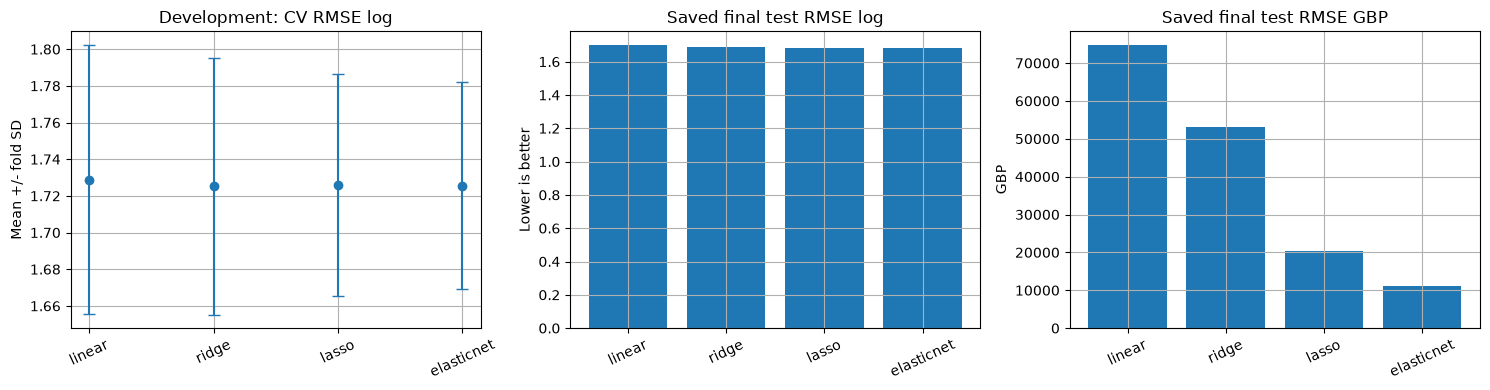

In [3]:
final_comparison = cv_summary[cv_metric_columns].join(test_summary.add_prefix("test_"))
final_comparison["selected_by_CV"] = final_comparison.index == winner
display(final_comparison)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].errorbar(cv_summary.index, cv_summary["mean_cv_rmse_log"],
                 yerr=cv_summary["std_cv_rmse_log"], fmt="o", capsize=4)
axes[0].set(title="Development: CV RMSE log", ylabel="Mean +/- fold SD")
axes[1].bar(test_summary.index, test_summary["rmse_log"])
axes[1].set(title="Saved final test RMSE log", ylabel="Lower is better")
axes[2].bar(test_summary.index, test_summary["rmse_gbp"])
axes[2].set(title="Saved final test RMSE GBP", ylabel="GBP")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

Lasso and ElasticNet beat Ridge on some final-test metrics, particularly
GBP RMSE/MAE. This matters as an honest limitation of the selected decision,
**not permission to retrospectively change it**. Ridge's CV minimum was
1.725261 versus ElasticNet 1.725480 and Lasso 1.726086.
Those differences are tiny relative to fold variability.

Ridge's test log R2 is **0.266016**: modest explained variation relative
to a mean reference, not a percentage accuracy. GBP RMSE **52,996.15**
and MAE **2,570.97** show that a tolerable-looking log comparison can conceal
unacceptable currency-space errors.

## 3. Coefficient statistics: actual availability, not invented comparisons

The joblib contains only the chosen full-data Ridge pipeline. Its
coefficients can be inspected, but the training-partition Ridge vector,
OLS/Lasso/ElasticNet vectors, and per-alpha paths were not saved.
The table below keeps the original test rows and the different coefficient
scope separate. Missing values mean **unavailable**, not zero coefficients.

In [4]:
ridge_pipeline, coefficients = ridge_coefficients()
coefficient_summary = pd.DataFrame(index=list(candidates), columns=[
    "coefficient_count", "L1_norm", "L2_norm", "exact_zero_count", "scope"
])
coefficient_summary["scope"] = "Unavailable: original fitted vector not saved"
coefficient_summary.loc["ridge"] = [
    len(coefficients), coefficients["absolute_coefficient"].sum(),
    np.linalg.norm(coefficients["coefficient"]),
    int(coefficients["coefficient"].eq(0).sum()),
    f"Packaged full-data refit only ({metadata['n_training_customers']} rows)"
]
display(coefficient_summary)
display(coefficients.sort_values("absolute_coefficient", ascending=False))
print("Intercept:", ridge_pipeline.named_steps["regressor"].intercept_)
print("This is an inspection of the saved artifact, not a new fit or holdout-model vector.")

2026-10-11 00:38:13.032 | INFO     | ecommerce_customer_value_prediction.models.train:load_model:339 - [load_model] Pipeline loaded from C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction\models\customer_value_model.joblib


,coefficient_count,L1_norm,L2_norm,exact_zero_count,scope
linear,NaN,NaN,NaN,NaN,Unavailable: original fitted vector not saved
ridge,47,11.26748,2.097173,0,Packaged full-data refit only (4374 rows)
lasso,NaN,NaN,NaN,NaN,Unavailable: original fitted vector not saved
elasticnet,NaN,NaN,NaN,NaN,Unavailable: original fitted vector not saved


,encoded_feature,coefficient,absolute_coefficient
33,cat__country_Norway,0.717195,0.717195
40,cat__country_Switzerland,0.695801,0.695801
17,cat__country_EIRE,-0.679377,0.679377
20,cat__country_France,0.610710,0.610710
16,cat__country_Denmark,0.608908,0.608908
0,num__recency_days,-0.496356,0.496356
22,cat__country_Greece,-0.476826,0.476826
45,cat__country_Unspecified,-0.397842,0.397842
25,cat__country_Italy,0.388262,0.388262
14,cat__country_Cyprus,0.373179,0.373179


Intercept: 1.3468035843894084
This is an inspection of the saved artifact, not a new fit or holdout-model vector.


## 4. Ridge error analysis: zeros can make the median reassuring

There are **566 zero-revenue** and **309 positive-revenue** test customers.
Zeros alone exceed half the test set. Their MAE is approximately **2.76 GBP**,
whereas positive customers have MAE approximately **7,275.19 GBP**.
Overall median absolute error **3.45 GBP** therefore cannot summarize the
quality of predictions for revenue-positive customers.

The saved `over_1000_gbp` group is **9 customers** with MAE approximately
**247,742.26 GBP**. It is a subset of the positive group; do not add its
count to zero+positive totals or treat all three rows as disjoint segments.

,n_customers,mae_gbp,mean_actual_gbp,mean_predicted_gbp
zero,566,2.761782,0.000000,2.741116
positive,309,7275.185233,161.802557,7191.897562
over_1000_gbp,9,247742.260550,3294.674444,246568.853181


Weighted MAE from saved disjoint segment summaries: 2570.966177980857
Recorded total MAE (rounded): 2570.97


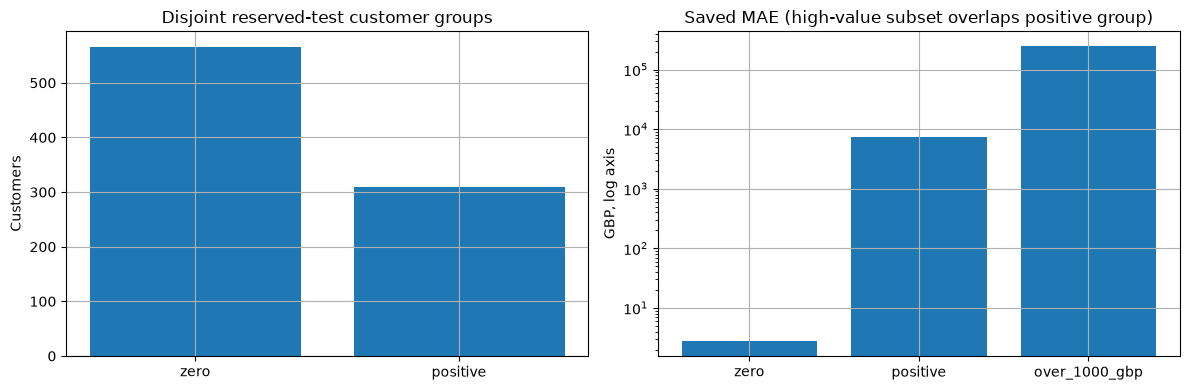

In [5]:
segments = pd.DataFrame(errors["segments"]).T
segments["n_customers"] = segments["n_customers"].astype(int)
display(segments)
assert segments.loc["zero", "n_customers"] + segments.loc["positive", "n_customers"] == 875
weighted_mae = (
    segments.loc[["zero", "positive"], "n_customers"]
    * segments.loc[["zero", "positive"], "mae_gbp"]
).sum() / 875
print("Weighted MAE from saved disjoint segment summaries:", weighted_mae)
print("Recorded total MAE (rounded):", test_summary.loc["ridge", "mae_gbp"])
assert np.isclose(weighted_mae, test_summary.loc["ridge", "mae_gbp"], atol=0.005)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["zero", "positive"], segments.loc[["zero", "positive"], "n_customers"])
axes[0].set(title="Disjoint reserved-test customer groups", ylabel="Customers")
axes[1].bar(segments.index, segments["mae_gbp"])
axes[1].set(yscale="log", title="Saved MAE (high-value subset overlaps positive group)",
            ylabel="GBP, log axis")
fig.tight_layout()
plt.show()

## 5. Low, medium, and high revenue: what was saved?

For a teaching segmentation one might use zero=0, low=(0,50],
medium=(50,1000], high=(1000,infinity) GBP. These proposed boundaries do
**not** change feature/target definitions or the original split.
The actual experiment saved zero, all-positive, and >1000 summaries only.

Low/medium counts and error metrics cannot be derived by splitting an
aggregate mean. Even with actual revenue data, the original held-out
prediction vector is missing. We do not apply the packaged full-data refit
to previously held-out customers: that model was trained on them, so its
errors would not recreate the original holdout experiment.

In [6]:
display(pd.DataFrame([
    ["zero", "actual=0", "566 rows; saved MAE 2.761782"],
    ["low (proposed)", "0 < actual <= 50", "Not saved; no row-level prediction artifact"],
    ["medium (proposed)", "50 < actual <= 1000", "Not saved; no row-level prediction artifact"],
    ["high (saved)", "actual > 1000", "9 rows; saved MAE 247742.260550"],
    ["positive (saved)", "actual > 0", "309 rows; overlaps low/medium/high"],
], columns=["Segment", "Definition in GBP", "Available evidence"]))

,Segment,Definition in GBP,Available evidence
0,zero,actual=0,566 rows; saved MAE 2.761782
1,low (proposed),0 < actual <= 50,Not saved; no row-level prediction artifact
2,medium (proposed),50 < actual <= 1000,Not saved; no row-level prediction artifact
3,high (saved),actual > 1000,9 rows; saved MAE 247742.260550
4,positive (saved),actual > 0,309 rows; overlaps low/medium/high


## 6. Largest underpredictions and overpredictions

Define a revenue residual \(e=r-\widehat r\). Positive means underprediction;
negative means overprediction. Ranking actual rows would require customer ID,
actual revenue, and the original held-out prediction per row. Those were not
saved, so **neither the top underprediction nor the top overprediction rows
can be shown truthfully**.

We can inspect aggregate signed behavior: predicted held-out mean is
**2,541.54 GBP**, actual mean **57.14 GBP**. The positive group has predicted
mean **7,191.90** versus actual **161.80**; the >1000 group has predicted mean
**246,568.85** versus actual **3,294.67**. This demonstrates substantial
aggregate overprediction. It does not mean every customer was overpredicted
or identify the sign/customer responsible for the maximum absolute error.

In [7]:
signed_summary = segments[["mean_actual_gbp", "mean_predicted_gbp"]].copy()
signed_summary["mean_actual_minus_prediction_gbp"] = (
    signed_summary["mean_actual_gbp"] - signed_summary["mean_predicted_gbp"]
)
display(signed_summary)
print("Overall signed mean residual:", errors["mean_actual_gbp"] - errors["mean_predicted_gbp"])
display(pd.DataFrame([
    ["Largest underprediction rows", "Unavailable: original row-level predictions not saved"],
    ["Largest overprediction rows", "Unavailable: original row-level predictions not saved"],
    ["Customer/sign of maximum absolute error", "Unavailable: aggregate maximum only"],
], columns=["Requested ranking", "Evidence boundary"]))

,mean_actual_gbp,mean_predicted_gbp,mean_actual_minus_prediction_gbp
zero,0.000000,2.741116,-2.741116
positive,161.802557,7191.897562,-7030.095006
over_1000_gbp,3294.674444,246568.853181,-243274.178737


Overall signed mean residual: -2484.4009465386894


,Requested ranking,Evidence boundary
0,Largest underprediction rows,Unavailable: original row-level predictions no...
1,Largest overprediction rows,Unavailable: original row-level predictions no...
2,Customer/sign of maximum absolute error,Unavailable: aggregate maximum only


## 7. The approximately GBP 1.20 million error is real saved evidence

The saved maximum absolute error is **1,195,100.6948878253 GBP**.
It is not a typo we corrected, a retraining result, or a clipped value.
In a squared-error metric, one huge error can dominate RMSE while leaving the
median almost unchanged.

Using the saved rounded RMSE, we can estimate how much of total squared
error this single maximum contributes. This is arithmetic on summaries,
not reevaluation. The exact customer's identity, residual sign, features,
and log prediction are unavailable, so attributing a specific cause would
go beyond the evidence.

In [8]:
maximum_error = errors["largest_absolute_error_gbp"]
n_test = int(test_summary.loc["ridge", "n_test_customers"])
saved_rmse = test_summary.loc["ridge", "rmse_gbp"]
approximate_sse = n_test * saved_rmse**2
maximum_sse_share = maximum_error**2 / approximate_sse
print(f"Maximum absolute error: GBP {maximum_error:,.2f}")
print(f"Maximum alone supplies at least RMSE: GBP {maximum_error / np.sqrt(n_test):,.2f}")
print(f"Approximate share of total squared GBP error: {100 * maximum_sse_share:.2f}%")
print("Approximation uses rounded saved RMSE; no per-row errors were reconstructed.")

Maximum absolute error: GBP 1,195,100.69
Maximum alone supplies at least RMSE: GBP 40,401.78
Approximate share of total squared GBP error: 58.12%
Approximation uses rounded saved RMSE; no per-row errors were reconstructed.


## 8. Why did the linear model produce 50 negative predictions?

The fitted response is an unrestricted affine function:
\(\widehat y=\beta_0+z^\mathsf{T}\beta\). Nonnegative training targets do
**not** constrain a least-squares prediction to be nonnegative. Some feature
combinations can produce \(\widehat y<0\).

The inverse transform is then \(\widehat r=\exp(\widehat y)-1<0\).
For finite negative log predictions, the mathematical range is (-1,0) GBP.
This explains the mechanism, not the missing individual customer rows.
The original experiment recorded **50/875 negative revenue predictions**.
They are impossible gross revenue estimates and a model limitation.
We do **not** silently clip them: clipping changes the prediction policy
and metrics and would need separate, prospective validation.

In [9]:
count_negative = errors["negative_predictions"]
print("Saved negative predictions:", count_negative, "of", n_test,
      f"({100 * count_negative / n_test:.2f}%)")
# Pure transform examples; not model outputs or test predictions.
illustrative_log = np.array([-2., -0.1, 0., 2., 14.])
display(pd.DataFrame({
    "illustrative_log_prediction": illustrative_log,
    "expm1_gbp_unclipped": np.expm1(illustrative_log),
}))

Saved negative predictions: 50 of 875 (5.71%)


,illustrative_log_prediction,expm1_gbp_unclipped
0,-2.0,-8.646647e-01
1,-0.1,-9.516258e-02
2,0.0,0.000000e+00
3,2.0,6.389056e+00
4,14.0,1.202603e+06


## 9. Why extreme customers remain hard after log transformation

1. **Heavy tails and few examples:** only nine held-out customers exceed
   1000 GBP. A global affine relationship cannot represent every unusual
   purchase trajectory. Segment means show very large errors, but no saved
   row data lets us diagnose the specific maximum-error case.
2. **Changed objective:** squared log errors compress extreme revenue.
   Reducing log RMSE does not guarantee small GBP errors.
3. **Exponential sensitivity:** \(d\widehat r/d\widehat y=\exp(\widehat y)\).
   The same log error has a much larger absolute GBP effect at a large log
   prediction. A log error of delta changes \(1+\widehat r\) by a factor
   \(\exp(\delta)\), so even modest errors can amplify dramatically.
4. **Unbounded extrapolation:** an affine predictor has no upper bound.
   Scaling and L2 regularization do not impose plausible revenue bounds.
   Exponentiating a large fitted value can magnify extrapolation.
5. **Zero inflation and mixed behavior:** one regression blends inactivity,
   small purchases, and rare large purchases, rather than representing all
   their mechanisms separately.
6. **Retransformation is not mean calibration:** `expm1` of a predicted log
   value is not generally the conditional mean revenue (Jensen's inequality).
   That alone does not explain these overprediction outliers. A generic
   upward smearing correction would not be justified by the saved diagnostics.

These are mechanisms and plausible risk factors, not a verified causal
explanation for a particular unsaved customer. Regularization cannot create
missing features, fix a truncated horizon, or guarantee temporal generalization.

## 10. Two separate readiness judgments

### SOFTWARE / PORTFOLIO READINESS: YES, educational prototype

Another developer can install the package, load the full fitted Pipeline,
supply the eight required fields, and generate single/batch predictions.
The prior completed implementation verified **238 tests**, cross-process
serialization at 1e-12 tolerance, schema errors, unknown countries,
checksum/version checks, and fresh-process inference with training forbidden.
This notebook reports that prior verification; it does not rerun training.
See [README](../README.md) and [model card](../reports/model_card.md).

### PREDICTIVE / BUSINESS READINESS: NO

Modest log R2, enormous currency-space errors, negative predictions, and no
temporal backtesting are insufficient for real customer-targeting decisions.
Accurate file loading is a software property, not evidence of commercial
value or reliable decision-making.

Production needs complete-horizon temporal backtests, fresh cohort validation,
revenue-space calibration/acceptance criteria, decision-cost evaluation,
input data contracts/history checks, monitoring, drift detection, retraining
triggers, versioning/rollback, and operational deployment controls.
Exact experiment reproduction also needs the original local dataset snapshot.
None of that work is simulated by switching models after seeing this test set.

## 11. What I learned

| Concept | Lesson from my completed experiment |
|---|---|
| OLS | Unpenalized least squares is the shared-feature control, not a business-ready forecast |
| Ridge | Adds L2 to stabilize coefficient directions; alpha=10 won saved CV |
| Lasso | Adds L1 and permits exact zeros; actual sparsity counts were not saved |
| ElasticNet | Blends L1/L2; locked alpha=0.1, l1_ratio=0.75 |
| Regularization | Changes fit/complexity balance; CV improvements here were small |
| alpha | Sets penalty strength; sklearn family normalization makes raw values incomparable |
| l1_ratio | Controls L1/L2 mixture, separate from total penalty strength |
| Cross-validation | Preprocessing is refitted within training folds; reserved test stays outside |
| Hyperparameter tuning | Original training-CV grid search chose family minima; these lessons do not tune |
| Test-set discipline | Final test evaluates a locked decision; it cannot retroactively select the winner |
| Coefficient shrinkage | L2 discourages large norms; unsaved paths prevent empirical cross-alpha claims |
| Sparsity | Zero coefficients are possible with L1, not proof of causal irrelevance |
| Error analysis | Median performance can hide severe tail errors; inspect segments and signed behavior |
| Model limitations | Unbounded log predictions can yield negative or explosive GBP outputs |

**My final takeaway:** the reusable inference software works, but the saved
evidence does not justify real customer-targeting decisions. Honest
limitations and evidence gaps are part of a credible ML portfolio.

In [10]:
for filename, original in initial_hashes.items():
    assert sha256(Path(filename)) == original, f"Artifact changed: {filename}"
current_files = {
    str(path) for directory in (EXPERIMENT, ROOT / "models")
    for path in directory.rglob("*") if path.is_file()
}
assert current_files == set(initial_hashes), "Protected artifact inventory changed."
assert Pipeline.fit is forbid_fit and GridSearchCV.fit is forbid_fit
print("PASS: no fitting/tuning; experiment and model artifact bytes/inventory unchanged.")

PASS: no fitting/tuning; experiment and model artifact bytes/inventory unchanged.
